# Exploring the data behind the predictor

This notebook looks at the matches and odds the model is built on, and links each finding to a choice in the pipeline: the baseline, Elo's home advantage, the features, the walk-forward test and the market benchmark.

**Which seasons are used.** Sections 1–5 justify modelling choices, so they use only the seasons before the final test (2015/16 to 2021/22): the data that was available when those choices were made. The final-test seasons (2022/23 onwards) are left out, so this notebook does not look at them. Sections 6 and 7 describe the bookmakers' odds, the benchmark the model is compared with; no modelling choice depends on them, so they use every season with odds (2019/20 onwards).

In [1]:
import sys
sys.path.insert(0, "..")   # the notebook runs from notebooks/, and src/ is one level up

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.backtest import FINAL_SEASONS
from src.db import read_sql
from src.evaluate import remove_margin
from src.features import load_features

pd.set_option("display.precision", 3)
plt.rcParams["figure.figsize"] = (8, 4)
LEAGUES = {"E0": "Premier League", "E1": "Championship"}

In [2]:
# One row per finished match with its pre-match Elo ratings and rolling form: the model's own inputs
features = load_features()
explore = features[~features["season"].isin(FINAL_SEASONS)].copy()

# Average odds across bookmakers, before the match (avg_) and at kick-off (close_)
odds = read_sql("""
    SELECT m.match_id, m.league, m.season, m.result,
           o.avg_home, o.avg_draw, o.avg_away, o.close_home, o.close_draw, o.close_away
    FROM matches m
    JOIN odds o ON o.match_id = m.match_id
""")
odds_cols = ["avg_home", "avg_draw", "avg_away", "close_home", "close_draw", "close_away"]
odds[odds_cols] = odds[odds_cols].astype(float)   # Postgres returns numbers as Decimal

print(f"Matches explored (2015/16 to 2021/22): {len(explore):,}")
print(f"Matches with odds (2019/20 onwards):   {len(odds):,}")
print("Missing odds values:", int(odds[odds_cols].isna().sum().sum()))

Matches explored (2015/16 to 2021/22): 6,524
Matches with odds (2019/20 onwards):   6,804
Missing odds values: 0


## 1. How often each result happens

The simplest forecast gives every match the same probabilities: how often home wins, draws and away wins happen in that league. Any model has to beat it.

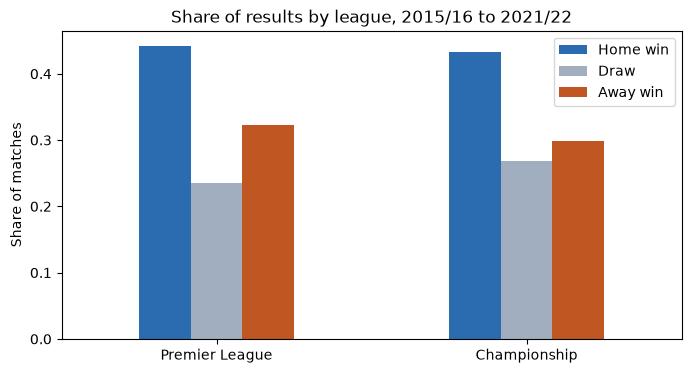

Log loss of the league-rate forecast: 1.0723


result,H,D,A
league,,,
Premier League,0.442,0.235,0.323
Championship,0.432,0.269,0.299


In [3]:
rates = explore.groupby("league")["result"].value_counts(normalize=True).unstack()[["H", "D", "A"]]
rates.index = rates.index.map(LEAGUES)

rates.plot(kind="bar", rot=0, color=["#2b6cb0", "#a0aec0", "#c05621"])
plt.title("Share of results by league, 2015/16 to 2021/22")
plt.ylabel("Share of matches")
plt.xlabel("")
plt.legend(["Home win", "Draw", "Away win"])
plt.show()

# Log loss of that forecast: minus the average log of the probability given to what happened
base = explore.groupby("league")["result"].value_counts(normalize=True)
picked = base.loc[list(zip(explore["league"], explore["result"]))].to_numpy()
print(f"Log loss of the league-rate forecast: {-np.log(picked).mean():.4f}")
rates

**What it shows.** Home wins are the most common result in both leagues (44% and 43%), but well short of a majority. The Championship has more draws (27% against 24%) and fewer away wins. Predicting each league's rates for every match gives a log loss of 1.072; this is the baseline in the walk-forward test (1.0733 on the final-test seasons), and the model has to do clearly better.

## 2. Home advantage, and the season without crowds

Elo gives the home team a fixed bonus of 60 rating points. For two equal teams that means an expected score of 0.585 for the home side, where a win counts 1 and a draw 0.5. Here is how big home advantage actually was each season. The 2020/21 season was played almost entirely without crowds, and so were the last weeks of 2019/20.

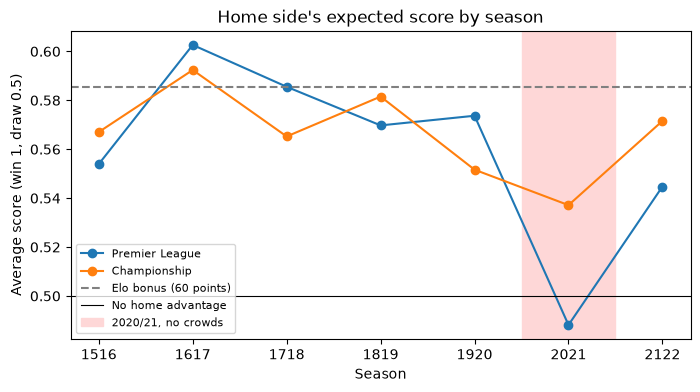

league,Premier League,Championship
season,,
1516,0.554,0.567
1617,0.603,0.592
1718,0.586,0.565
1819,0.570,0.582
1920,0.574,0.552
2021,0.488,0.537
2122,0.545,0.572


In [4]:
# Expected score of the home side: a win counts 1, a draw 0.5
explore["home_score"] = explore["result"].map({"H": 1.0, "D": 0.5, "A": 0.0})
by_season = explore.groupby(["season", "league"])["home_score"].mean().unstack()
by_season.columns = by_season.columns.map(LEAGUES)

elo_home = 1 / (1 + 10 ** (-60 / 400))   # what the 60-point bonus means for two equal teams
ax = by_season.plot(marker="o")
ax.axhline(elo_home, color="grey", linestyle="--", label="Elo bonus (60 points)")
ax.axhline(0.5, color="black", linewidth=0.8, label="No home advantage")
ax.axvspan(4.5, 5.5, color="#fed7d7", label="2020/21, no crowds")
plt.title("Home side's expected score by season")
plt.ylabel("Average score (win 1, draw 0.5)")
plt.xlabel("Season")
plt.legend(fontsize=8)
plt.show()
by_season.round(3)

**What it shows.** In a season where every pair of teams meets home and away, team strength evens out, so the season average measures home advantage itself. In normal seasons the home side scored 0.55 to 0.60, about 0.57 on average in both leagues. Elo's 60-point bonus (0.585) is a little above that; 0.57 corresponds to about 50 points.

In 2020/21, without crowds, home advantage disappeared in the Premier League (0.488, slightly below no advantage at all) and shrank in the Championship (0.537), then returned in 2021/22. **Decision:** a single home-advantage value works for normal seasons, but it cannot follow a season like 2020/21, and that season sits inside the tuning period. Any period without crowds would hurt the model the same way.

## 3. Goals and draws over time

If scoring or the draw rate drifts from season to season, a model fitted once on old seasons goes stale. That is why the model is retrained before each season in the walk-forward test.

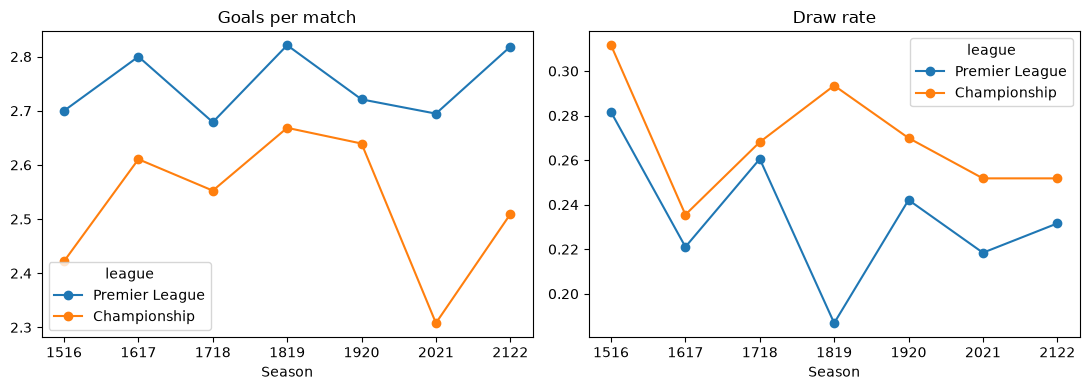

goals_per_match        draw_rate       
league              E0     E1        E0     E1
season                                        
1516             2.700  2.422     0.282  0.312
1617             2.800  2.611     0.221  0.236
1718             2.679  2.553     0.261  0.268
1819             2.821  2.668     0.187  0.293
1920             2.721  2.639     0.242  0.270
2021             2.695  2.308     0.218  0.252
2122             2.818  2.509     0.232  0.252

In [5]:
goals = read_sql("""
    SELECT league, season, AVG(home_goals + away_goals) AS goals_per_match, AVG((result = 'D')::int) AS draw_rate
    FROM matches
    GROUP BY league, season
    ORDER BY season
""")
goals = goals[~goals["season"].isin(FINAL_SEASONS)]
goals[["goals_per_match", "draw_rate"]] = goals[["goals_per_match", "draw_rate"]].astype(float)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for column, ax, title in [("goals_per_match", axes[0], "Goals per match"), ("draw_rate", axes[1], "Draw rate")]:
    goals.pivot(index="season", columns="league", values=column).rename(columns=LEAGUES).plot(marker="o", ax=ax)
    ax.set_title(title)
    ax.set_xlabel("Season")
plt.tight_layout()
plt.show()
goals.pivot(index="season", columns="league", values=["goals_per_match", "draw_rate"]).round(3)

**What it shows.** Premier League scoring is steady at 2.7 to 2.8 goals a match. The Championship moves more (2.3 to 2.7), with its low point in 2020/21. The draw rate swings from 19% to 28% in the Premier League. With 380 matches a season, chance alone moves a 24% rate by about 2 points either way, so much of that swing is noise, and that noise is itself why draws are the hardest result to predict. **Decision:** because the leagues do change, as in 2020/21, the model is retrained before each test season (the walk-forward test) instead of being fitted once.

## 4. The rating gap

`elo_diff` is the home team's Elo minus the away team's, before the match. If it carries the signal the model relies on, the home-win share should rise steadily with it.

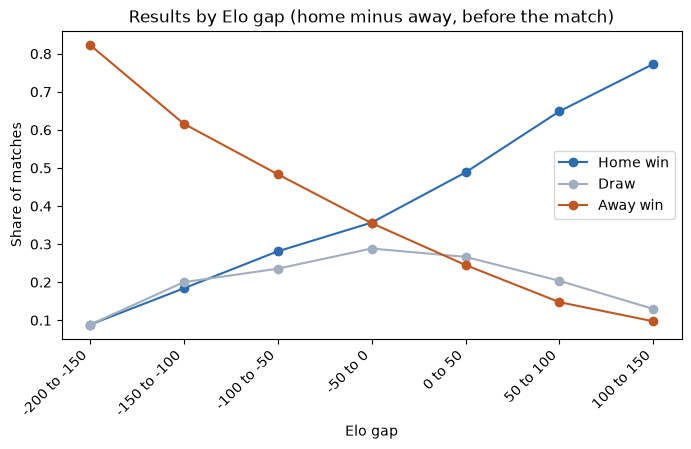

result,H,D,A,matches
elo_bin,,,,
< -200,NaN,NaN,1.000,2
-200 to -150,0.088,0.088,0.824,34
-150 to -100,0.184,0.200,0.616,185
-100 to -50,0.281,0.235,0.484,790
-50 to 0,0.356,0.288,0.355,2264
0 to 50,0.488,0.267,0.245,2236
50 to 100,0.649,0.204,0.148,766
100 to 150,0.773,0.130,0.097,216
150 to 200,0.808,0.115,0.077,26


In [6]:
bins = [-np.inf, -200, -150, -100, -50, 0, 50, 100, 150, 200, np.inf]
labels = ["< -200", "-200 to -150", "-150 to -100", "-100 to -50", "-50 to 0",
          "0 to 50", "50 to 100", "100 to 150", "150 to 200", "> 200"]
explore["elo_bin"] = pd.cut(explore["elo_diff"], bins=bins, labels=labels)

by_gap = explore.groupby("elo_bin", observed=True)["result"].value_counts(normalize=True).unstack()[["H", "D", "A"]]
counts = explore["elo_bin"].value_counts().reindex(labels)

# Groups with fewer than 30 matches are too small to read, so they stay out of the chart (not the table)
shown = by_gap[counts.reindex(by_gap.index) >= 30]
ax = shown.plot(marker="o", color=["#2b6cb0", "#a0aec0", "#c05621"])
ax.set_xticks(range(len(shown)))
ax.set_xticklabels(shown.index, rotation=45, ha="right")
plt.title("Results by Elo gap (home minus away, before the match)")
plt.ylabel("Share of matches")
plt.xlabel("Elo gap")
plt.legend(["Home win", "Draw", "Away win"])
plt.show()
by_gap.assign(matches=counts).round(3)

**What it shows.** The home-win share rises steadily with the Elo gap, from 18% at -150 to -100 to 77% at 100 to 150, and away wins fall the other way, so the rating carries a strong signal. Draws peak at 29% for the closest matches (-50 to 0, where the home bonus balances the gap) and fall to about 12% when one side is much stronger. Most matches are close: about 70% of them fall between -50 and +50, where no result has more than about a 50% chance. That limits how good any forecast can be. The three most extreme groups hold only 33 matches between them, so they appear in the table but not on the chart.

## 5. Does shots-on-target form add anything to Elo?

The model also uses each team's shots on target for and against over its last five matches. One number sums them up: the **shots-on-target edge**, the home side's (for minus against) minus the away side's. It only earns its place if it says something Elo does not already say, so the check is made within groups of matches with a similar Elo gap.

Correlation between the shots-on-target edge and the Elo gap: 0.54


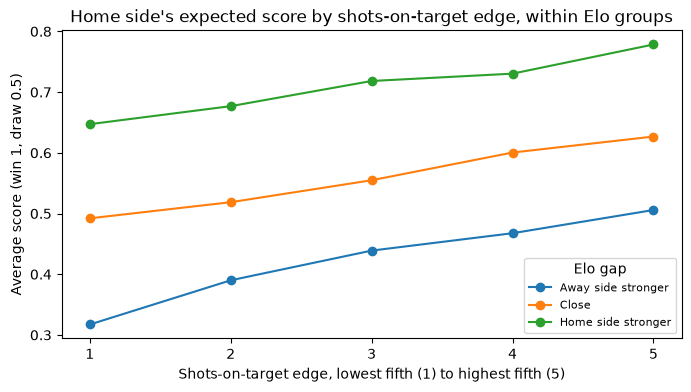

elo_group,Away side stronger,Close,Home side stronger
sot_group,,,
1,0.317,0.492,0.647
2,0.390,0.519,0.677
3,0.439,0.555,0.718
4,0.468,0.600,0.730
5,0.506,0.627,0.778


In [7]:
form = explore.dropna(subset=["home_sot5", "home_sota5", "away_sot5", "away_sota5"]).copy()
form["sot_edge"] = (form["home_sot5"] - form["home_sota5"]) - (form["away_sot5"] - form["away_sota5"])
print(f"Correlation between the shots-on-target edge and the Elo gap: {form['sot_edge'].corr(form['elo_diff']):.2f}")

# Split matches into three Elo groups, then into five shots-on-target groups within each
form["elo_group"] = pd.qcut(form["elo_diff"], 3, labels=["Away side stronger", "Close", "Home side stronger"])
form["sot_group"] = form.groupby("elo_group", observed=True)["sot_edge"].transform(
    lambda x: pd.qcut(x, 5, labels=False) + 1)
within = form.groupby(["elo_group", "sot_group"], observed=True)["home_score"].mean().unstack(0)

within.plot(marker="o")
plt.title("Home side's expected score by shots-on-target edge, within Elo groups")
plt.xlabel("Shots-on-target edge, lowest fifth (1) to highest fifth (5)")
plt.ylabel("Average score (win 1, draw 0.5)")
plt.xticks(range(1, 6))
plt.legend(title="Elo gap", fontsize=8)
plt.show()
within.round(3)

**What it shows.** The shots-on-target edge is correlated with the Elo gap (0.54), so the two overlap. Within each Elo group, though, the home side's score still rises steadily from the lowest to the highest fifth of the edge: by 19 points when the away side is stronger, 14 in close matches and 13 when the home side is stronger. So recent shots on target carry information that Elo has not absorbed yet, such as a team improving or declining faster than its rating moves. The Elo groups are wide, so part of the rise may still be Elo within a group. The formal check, adding the features to the model and scoring it on unseen seasons, is in `src/feature_test.py`. **Decision:** shots-on-target form is used alongside Elo.

## 6. The bookmakers' margin

Bookmakers' odds add up to more than 100% once turned into probabilities: the extra is their margin. `remove_margin` divides it out before the odds are compared with the model. Here is how big it is, before the match and at kick-off.

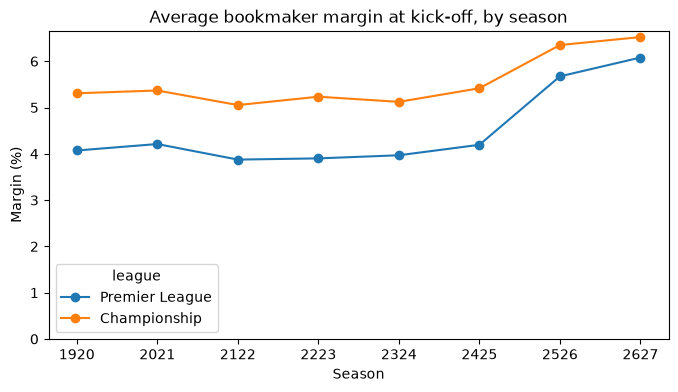

margin_pre  margin_close
league season                          
E0     1920          4.27          4.07
       2021          4.35          4.21
       2122          4.07          3.87
       2223          4.07          3.90
       2324          4.14          3.97
       2425          4.49          4.19
       2526          5.81          5.67
       2627          6.31          6.08
E1     1920          5.44          5.31
       2021          5.46          5.37
       2122          5.18          5.05
       2223          5.41          5.23
       2324          5.36          5.12
       2425          5.73          5.42
       2526          6.45          6.35
       2627          6.54          6.52

In [8]:
def margin(df, prefix):
    """Sum of 1/odds minus 1: the bookmakers' margin on each match."""
    return 1 / df[f"{prefix}_home"] + 1 / df[f"{prefix}_draw"] + 1 / df[f"{prefix}_away"] - 1

odds["margin_pre"] = margin(odds, "avg")
odds["margin_close"] = margin(odds, "close")
margins = odds.groupby(["league", "season"])[["margin_pre", "margin_close"]].mean().mul(100)

ax = margins.unstack(0)["margin_close"].rename(columns=LEAGUES).plot(marker="o")
plt.title("Average bookmaker margin at kick-off, by season")
plt.ylabel("Margin (%)")
plt.xlabel("Season")
plt.ylim(bottom=0)
plt.show()
margins.round(2)

**What it shows.** The closing margin is slightly smaller than the pre-match one. It was about 4% in the Premier League and 5% in the Championship until 2024/25, then rose to about 6% in both. These are averages across bookmakers, so the rise means the average price got worse, not one bookmaker. **Decision:** the comparison is unaffected, because the margin is removed before any comparison. `remove_margin` spreads it over the three outcomes in proportion to their probability. Section 7 checks how well that works.

## 7. How good the market is

Closing odds, with the margin removed, are the benchmark the model is compared with. A forecast is **calibrated** when outcomes it gives 30% happen about 30% of the time. Below, every outcome of every match is grouped by the probability the market gave it.

Pre-match odds log loss: 1.0103
Closing odds log loss: 1.0081


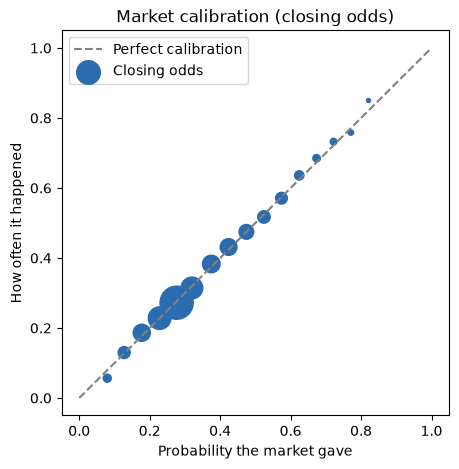

,predicted,actual,outcomes,gap
bin,,,,
"(0.05, 0.1]",0.080,0.057,336,-0.023
"(0.1, 0.15]",0.128,0.130,755,0.002
"(0.15, 0.2]",0.178,0.186,1524,0.009
"(0.2, 0.25]",0.228,0.228,2643,-0.000
"(0.25, 0.3]",0.277,0.272,5711,-0.004
"(0.3, 0.35]",0.320,0.314,2459,-0.005
"(0.35, 0.4]",0.375,0.383,1601,0.008
"(0.4, 0.45]",0.424,0.431,1458,0.007
"(0.45, 0.5]",0.474,0.475,1125,0.000


In [9]:
outcomes = {"home": "H", "draw": "D", "away": "A"}
rows = []
for prefix in ["avg", "close"]:
    probs = remove_margin(odds[[f"{prefix}_home", f"{prefix}_draw", f"{prefix}_away"]])
    probs.columns = list(outcomes)
    for name, code_ in outcomes.items():
        rows.append(pd.DataFrame({"odds": prefix, "outcome": name, "prob": probs[name],
                                  "happened": (odds["result"] == code_).astype(int)}))
long = pd.concat(rows, ignore_index=True)

# Log loss of each set of odds on the same matches
for prefix, label in [("avg", "Pre-match"), ("close", "Closing")]:
    happened = long[(long["odds"] == prefix) & (long["happened"] == 1)]
    print(f"{label} odds log loss: {-np.log(happened['prob']).mean():.4f}")

close = long[long["odds"] == "close"].copy()
edges = np.arange(0, 1.05, 0.05)
close["bin"] = pd.cut(close["prob"], edges)
calib = close.groupby("bin", observed=True).agg(predicted=("prob", "mean"), actual=("happened", "mean"),
                                                outcomes=("happened", "size"))
calib = calib[calib["outcomes"] >= 50]   # leave out bins too small to read

plt.figure(figsize=(5, 5))
plt.plot([0, 1], [0, 1], color="grey", linestyle="--", label="Perfect calibration")
plt.scatter(calib["predicted"], calib["actual"], s=calib["outcomes"] / 10, color="#2b6cb0", label="Closing odds")
plt.title("Market calibration (closing odds)")
plt.xlabel("Probability the market gave")
plt.ylabel("How often it happened")
plt.legend()
plt.show()
calib.assign(gap=calib["actual"] - calib["predicted"]).round(3)

**What it shows.** Closing odds beat the pre-match average (log loss 1.0081 against 1.0103 on the same matches), because they include the latest team news and money. They are also very well calibrated: from 10% to 75%, outcomes happen within about one percentage point of the probability given. The only gaps are at the extremes. Outcomes priced at 5 to 10% happened 5.7% of the time, not 8%, and favourites priced above 80% won more often than priced. This is the familiar favourite-longshot bias, here small and based on few matches. **Decision:** closing odds are the benchmark to beat. They are a hard one, and on the final-test seasons the model closed 74% of the gap between the baseline and the market without beating it (see the README).

## Summary

| Finding | Where it is used |
|---|---|
| Home wins 43–44%, draws 24–27%; the league-rate forecast scores 1.072 | The baseline in the walk-forward test |
| Home advantage is worth about 0.57 in a normal season, and vanished without crowds | Elo's fixed home bonus (60 points); a known weakness in seasons like 2020/21 |
| Scoring shifts between seasons, and draw rates are noisy | Retraining before every test season (walk-forward) |
| The Elo gap orders results strongly, but 70% of matches are close | Elo is the main feature; close matches limit any forecast |
| Shots-on-target form adds signal within every Elo group | Used next to Elo (confirmed in `src/feature_test.py`) |
| Margins of 4–6%, a little lower at kick-off | Removed with `remove_margin` before comparing |
| Closing odds beat pre-match odds and are calibrated within about a point | Closing odds are the benchmark |